# Классификация изображений Fashion MNIST

## Цель работы

Последовательно исследовать влияние архитектуры модели на качество
классификации изображений одежды:

1. Полносвязная нейронная сеть.
2. Свёрточная нейронная сеть.
3. Свёрточная сеть с аугментациями.
4. Свёрточная сеть с аугментациями и остаточной связью.

Во всех экспериментах используется одинаковое разбиение данных.
Тестовая выборка не участвует в подборе архитектуры и гиперпараметров.

# Подготовка данных

### 1. Зависимости

In [2]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Делает вычисления более воспроизводимыми.
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

Seed нужен, чтобы разбиение данных, начальные веса и другие случайные операции воспроизводились при повторном запуске.

### 2. Загрузка Fashion MNIST

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

class_names = [
    "Футболка/топ",
    "Брюки",
    "Пуловер",
    "Платье",
    "Пальто",
    "Сандалии",
    "Рубашка",
    "Кроссовки",
    "Сумка",
    "Ботинки",
]

print("Полная обучающая выборка:", x_train_full.shape)
print("Метки обучающей выборки:", y_train_full.shape)
print("Тестовая выборка:", x_test.shape)
print("Метки тестовой выборки:", y_test.shape)
print("Тип данных:", x_train_full.dtype)
print("Диапазон пикселей:", x_train_full.min(), "—", x_train_full.max())

Полная обучающая выборка: (60000, 28, 28)
Метки обучающей выборки: (60000,)
Тестовая выборка: (10000, 28, 28)
Метки тестовой выборки: (10000,)
Тип данных: uint8
Диапазон пикселей: 0 — 255


### 3. Примеры изображений

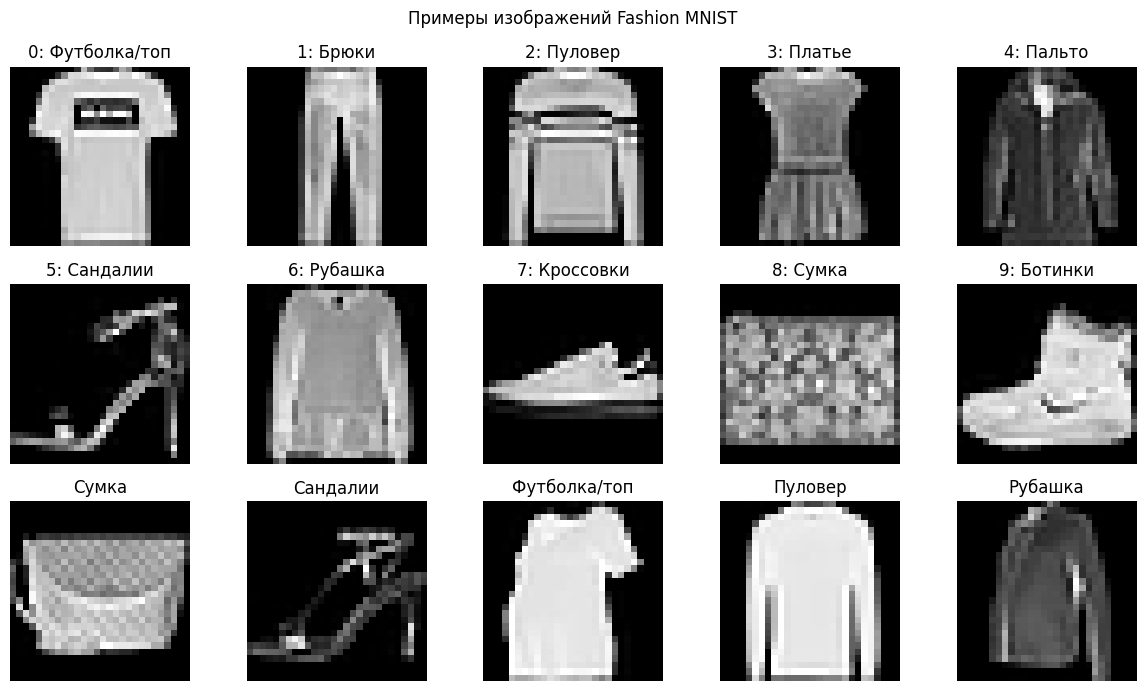

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for class_id, ax in enumerate(axes.flat[:10]):
    image_index = np.where(y_train_full == class_id)[0][0]
    
    ax.imshow(x_train_full[image_index], cmap="gray")
    ax.set_title(f"{class_id}: {class_names[class_id]}")
    ax.axis("off")

# Последние пять позиций заполним случайными примерами
rng = np.random.default_rng(SEED)
random_indices = rng.choice(len(x_train_full), size=5, replace=False)

for ax, image_index in zip(axes.flat[10:], random_indices):
    label = y_train_full[image_index]
    ax.imshow(x_train_full[image_index], cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
    
plt.suptitle("Примеры изображений Fashion MNIST")
plt.tight_layout()
plt.show()

### 4. Неизменное train/validation-разбиение

In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=10_000,
    random_state=SEED,
    stratify=y_train_full,    # Cохранит примерно одинаковое соотношение классов
    shuffle=True
)

print("Обучающая выборка:", x_train.shape, y_train.shape)
print("Валидационная выборка:", x_val.shape, y_val.shape)
print("Тестовая выборка:", x_test.shape, y_test.shape)

Обучающая выборка: (50000, 28, 28) (50000,)
Валидационная выборка: (10000, 28, 28) (10000,)
Тестовая выборка: (10000, 28, 28) (10000,)


Нормализуем изображения и добавим канал. Тогда одни и те же массивы подойдут как полносвязной, так и свёрточным моделям.

In [6]:
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Добавляем канал
x_train = x_train[..., np.newaxis]
x_val = x_val[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("После предобработки:")
print("x_train:", x_train.shape)
print("x_val:", x_val.shape)
print("x_test:", x_test.shape)
print("Диапазон:", x_train.min(), "—", x_train.max())

После предобработки:
x_train: (50000, 28, 28, 1)
x_val: (10000, 28, 28, 1)
x_test: (10000, 28, 28, 1)
Диапазон: 0.0 — 1.0


### 5. Проверка распределения классов

In [7]:
def class_distribution(labels, split_name):
    counts = np.bincount(labels, minlength=len(class_names))
    
    return pd.DataFrame({
        "Выборка": split_name,
        "Класс": np.arange(len(class_names)),
        "Название": class_names,
        "Количество": counts
    })

In [8]:
distribution = pd.concat(
    [
        class_distribution(y_train, "Train"),
        class_distribution(y_val, "Validation"),
        class_distribution(y_test, "Test"),
    ],
    ignore_index=True,
)

distribution.pivot(
    index=["Класс", "Название"],
    columns="Выборка",
    values="Количество",
)

,Выборка,Test,Train,Validation
Класс,Название,,,
0,Футболка/топ,1000,5000,1000
1,Брюки,1000,5000,1000
2,Пуловер,1000,5000,1000
3,Платье,1000,5000,1000
4,Пальто,1000,5000,1000
5,Сандалии,1000,5000,1000
6,Рубашка,1000,5000,1000
7,Кроссовки,1000,5000,1000
8,Сумка,1000,5000,1000


Fashion MNIST сбалансирован

### Вывод по подготовке данных

Fashion MNIST содержит 60 000 обучающих и 10 000 тестовых
полутоновых изображений размером 28×28 пикселей, разделённых на 10
сбалансированных классов.

Из исходной обучающей части выделено 10 000 изображений для
валидации. Разбиение выполнено со стратификацией и фиксированным
seed, поэтому оно будет одинаковым во всех экспериментах.

Значения пикселей нормализованы из диапазона [0, 255] в диапазон
[0, 1]. Тестовая выборка сохранена отдельно и пока не используется.

# Эксперимент 1. Полносвязная нейронная сеть

Изображение разворачивается в вектор из 784 признаков. Затем оно обрабатывается двумя полносвязными слоями. Для уменьшения переобучения используется Dropout.

### 1. Общие настройки обучения

In [9]:
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 1e-3

histories = {}
models = {}
experiment_results = {}

os.makedirs("checkpoints", exist_ok=True)

### 2. Архитектура модели

In [10]:
def build_dense_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        
        # Преобразование изображения 28×28×1 в вектор из 784 чисел
        tf.keras.layers.Flatten(),
        
        tf.keras.layers.Dense(256, activation="relu", name="dense_256"),
        tf.keras.layers.Dropout(0.30),
        
        tf.keras.layers.Dense(128, activation="relu", name="dense_128"),
        tf.keras.layers.Dropout(0.20),
        
        # 10 выходов — по одному для каждого класса
        tf.keras.layers.Dense(10, activation="softmax", name="predictions")
    ], name="dense_model")
    
    return model

In [11]:
dense_model = build_dense_model()
dense_model.summary()

Model: "dense_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Компиляция

In [12]:
dense_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

Почему именно такие настройки:
- Adam — устойчивый базовый оптимизатор;
- SparseCategoricalCrossentropy подходит, потому что метки представлены числами 0–9;
- softmax превращает выходы в вероятности классов;
- accuracy показывает долю правильных ответов.

### 4. Callback-функции

In [13]:
dense_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="checkpoints/dense_best.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

`EarlyStopping` остановит обучение, если `val_loss` не улучшается пять эпох подряд. `restore_best_weights=True` вернёт веса лучшей эпохи, а не последней.

`ModelCheckpoint` дополнительно сохранит лучшую модель в файл.

### 5. Обучение

In [14]:
dense_history = dense_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=dense_callbacks,
    verbose=1
)

histories["dense"] = dense_history
models["dense"] = dense_model

Epoch 1/30
381/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6986 - loss: 0.8590
Epoch 1: val_loss improved from None to 0.39565, saving model to checkpoints/dense_best.keras

Epoch 1: finished saving model to checkpoints/dense_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7779 - loss: 0.6256 - val_accuracy: 0.8573 - val_loss: 0.3957
Epoch 2/30
384/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8348 - loss: 0.4513
Epoch 2: val_loss improved from 0.39565 to 0.36710, saving model to checkpoints/dense_best.keras

Epoch 2: finished saving model to checkpoints/dense_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8413 - loss: 0.4377 - val_accuracy: 0.8669 - val_loss: 0.3671
Epoch 3/30
388/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8514 - loss: 0.4036
Epoch 3: val_loss improved from 0.36710 to 0.34473, saving model to checkpoints/dense_best.keras

Epoch 3: finished saving model to checkpoints/dense_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━

Не передаём в fit() тестовую выборку. Она остаётся полностью скрытой от процесса обучения и выбора модели.

### 6. Графики loss и accuracy

In [15]:
def plot_training_history(history, title):
    history_data = history.history
    epochs_range = range(1, len(history_data["loss"]) + 1)
    
    best_epoch = np.argmin(history_data["val_loss"]) + 1
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss
    axes[0].plot(epochs_range, history_data["loss"], label="Train loss", linewidth=2)
    axes[0].plot(epochs_range, history_data["val_loss"], label="Validation loss", linewidth=2)
    axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Лучшая эпоха: {best_epoch}")
    axes[0].set_title("Функция потерь")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    
    # Accuracy
    axes[1].plot(epochs_range, history_data["accuracy"], label="Train accuracy", linewidth=2)
    axes[1].plot(epochs_range, history_data["val_accuracy"], label="Validation accuracy", linewidth=2)
    axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Лучшая эпоха: {best_epoch}")
    axes[1].set_title("Точность")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

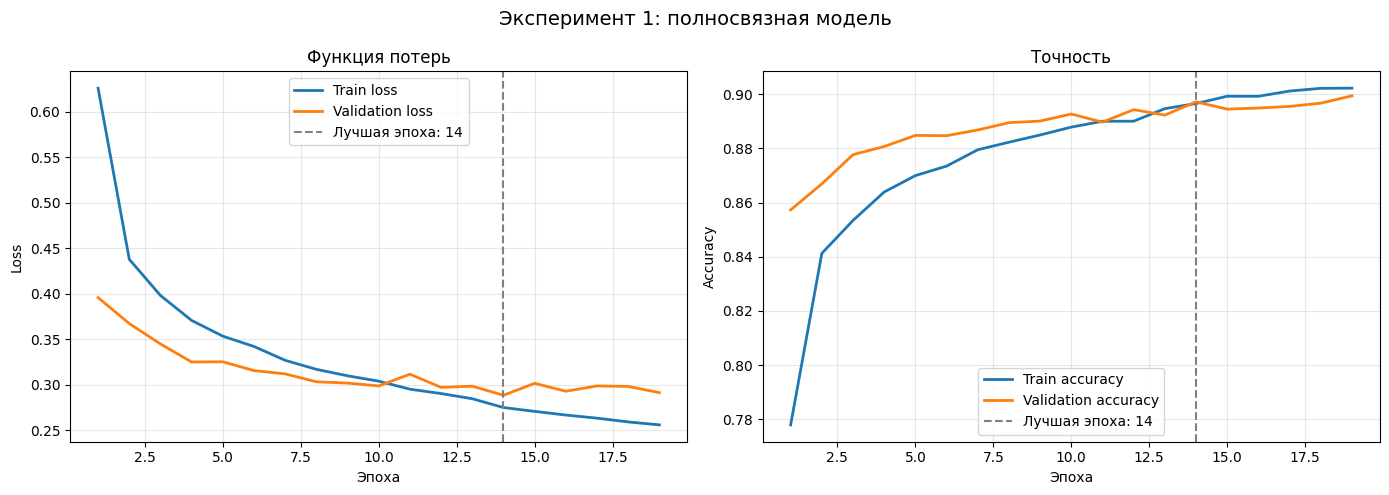

In [16]:
plot_training_history(
    dense_history,
    "Эксперимент 1: полносвязная модель",
)

### 7. Результаты на валидации

In [17]:
dense_val_losses = dense_history.history["val_loss"]
dense_val_accuracies = dense_history.history["val_accuracy"]

dense_best_epoch = int(np.argmin(dense_val_losses))
dense_min_val_loss = float(dense_val_losses[dense_best_epoch])
dense_val_accuracy_at_best = float(dense_val_accuracies[dense_best_epoch])

dense_parameters = dense_model.count_params()

experiment_results["dense"] = {
    "Номер": 1,
    "Модель": "Полносвязная сеть",
    "Параметры": dense_parameters,
    "Лучшая эпоха": dense_best_epoch + 1,
    "Минимальный val_loss": dense_min_val_loss,
    "val_accuracy": dense_val_accuracy_at_best
}

pd.DataFrame([experiment_results["dense"]])

,Номер,Модель,Параметры,Лучшая эпоха,Минимальный val_loss,val_accuracy
0,1,Полносвязная сеть,235146,14,0.288408,0.8972


Лучшая эпоха определяется по минимальному `val_loss`, а не по максимальному `val_accuracy`. Это заранее выбранное и единое правило для всех экспериментов.

### Вывод по эксперименту 1

Полносвязная модель содержит 235 146 обучаемых параметров. Минимальное значение validation loss составило **0.288408** и было достигнуто на эпохе **14**. Точность на валидационной выборке на этой эпохе составила **0.8972**.

По графикам видно, что в начале обучения значения `train loss` и `validation loss` уменьшаются, а точность на обеих выборках растёт. Это показывает, что модель успешно обучается и находит закономерности в данных.

Обучающая точность выше валидационной. Такой разрыв ожидаем, поскольку модель непосредственно оптимизируется на обучающей выборке. Наличие разрыва также указывает на некоторое переобучение модели.

После 14-й эпохи `validation loss` перестаёт устойчиво уменьшаться, в то время как качество на обучающей выборке продолжает улучшаться. Следовательно, дальнейшее обучение уже не улучшает обобщающую способность модели. Благодаря `EarlyStopping` были восстановлены веса соответствующие минимальному `validation loss`.

Полносвязная модель не учитывает пространственное расположение пикселей: слой Flatten превращает изображение в обычный вектор.
Следующий эксперимент проверит, даст ли сохранение пространственной структуры с помощью свёрточных слоёв лучшее качество.

# Эксперимент 2. Свёрточная нейронная сеть

В отличие от полносвязной сети, свёрточные слои обрабатывают локальные области изображения и сохраняют информацию о взаимном расположении пикселей.

Для уменьшения пространственного размера карт признаков используется MaxPooling. В конце карты признаков разворачиваются в вектор и передаются полносвязному классификатору.

### 1. Создание модели

In [18]:
def build_cnn_model():
    inputs = tf.keras.layers.Input(shape=(28, 28, 1), name="input_image")
    
    # 28x28x1 -> 28x28x32
    x = tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding="same", activation="relu", name="stem_conv")(inputs)
    # 28x28x32 -> 14x14x32
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_1")(x)
    
    # Свёрточный блок
    x = tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding="same", activation="relu", name="block_conv_1")(x)
    x = tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding="same", activation="relu", name="block_conv_2")(x)
    # 14×14×32 → 7×7×32
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_2")(x)
    # 7x7x32 -> 7x7x64
    x = tf.keras.layers.Conv2D(filters=64, kernel_size=3, padding="same", activation="relu", name="final_conv")(x)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    
    x = tf.keras.layers.Dense(64, activation="relu", name="classifier_dense")(x)
    x = tf.keras.layers.Dropout(0.30, name="classifier_dropout")(x)
    
    outputs = tf.keras.layers.Dense(10, activation="softmax", name="predictions")(x)
    
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="cnn_model")
    return model    
    
    
    
        

Создаем модель

In [19]:
# Возвращаем seed к исходному значению перед созданием модели
tf.keras.utils.set_random_seed(SEED)

cnn_model = build_cnn_model()
cnn_model.summary()

Model: "cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block_conv_1 (Conv2D)           │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block_conv_2 (Conv2D)           │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_conv (Conv2D)             │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,730 (932.54 KB)

 Trainable params: 238,730 (932.54 KB)

 Non-trainable params: 0 (0.00 B)

В первом свёрточном слое создаются 32 фильтра размером `3×3`. Каждый фильтр перемещается по изображению и может научиться распознавать определённый локальный признак:
- горизонтальные и вертикальные границы;
- углы;
- контуры одежды;
- элементы текстуры.
  
В более глубоких слоях простые признаки объединяются в более сложные формы.

### 2. Компиляция модели

Настройки должны совпадать с первым экспериментом

In [20]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)


### 3. Callback функции

Это список callback-функций — объектов, которые Keras вызывает во время обучения. Они следят за val_loss, останавливают обучение и сохраняют лучшую модель.

In [21]:
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="checkpoints/cnn_best.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

### 4. Обучение

In [22]:
cnn_history = cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cnn_callbacks,
    verbose=1
)

histories["cnn"] = cnn_history
models["cnn"] = cnn_model

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6670 - loss: 0.9138
Epoch 1: val_loss improved from None to 0.36401, saving model to checkpoints/cnn_best.keras

Epoch 1: finished saving model to checkpoints/cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.7717 - loss: 0.6311 - val_accuracy: 0.8664 - val_loss: 0.3640
Epoch 2/30
389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8535 - loss: 0.4017
Epoch 2: val_loss improved from 0.36401 to 0.30445, saving model to checkpoints/cnn_best.keras

Epoch 2: finished saving model to checkpoints/cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8616 - loss: 0.3846 - val_accuracy: 0.8924 - val_loss: 0.3045
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8786 - loss: 0.3369
Epoch 3: val_loss improved from 0.30445 to 0.27418, saving model to checkpoints/cnn_best.keras

Epoch 3: finished saving model to checkpoints/cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21

### 5. Графики обучения

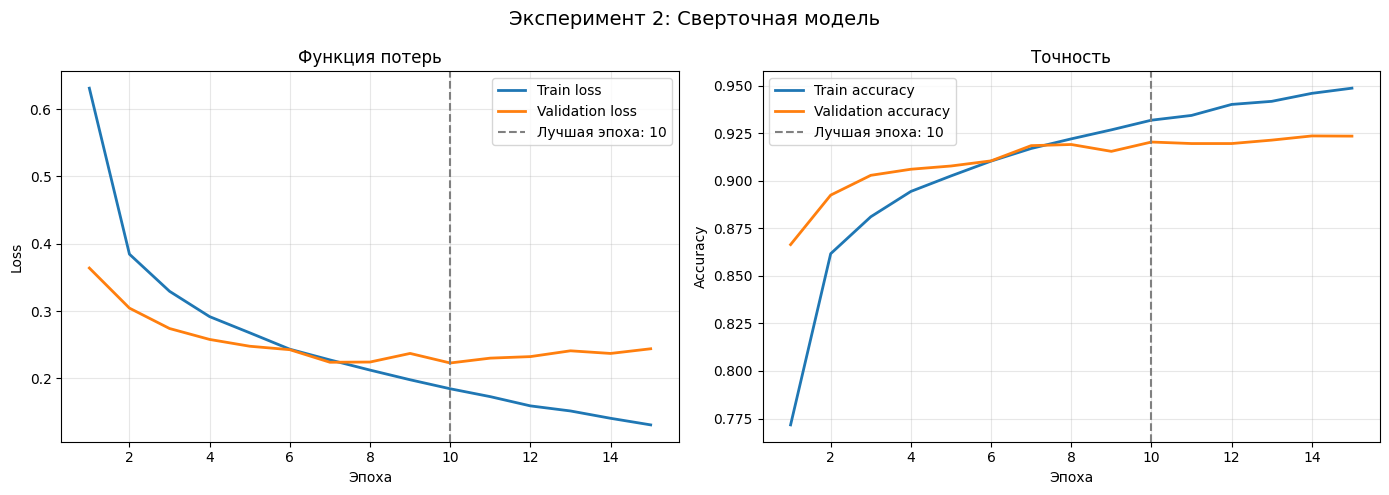

In [23]:
plot_training_history(cnn_history, "Эксперимент 2: Сверточная модель")

### 6. Сохранение результатов

In [24]:
cnn_val_losses = cnn_history.history["val_loss"]
cnn_val_accuracies = cnn_history.history["val_accuracy"]

cnn_best_epoch_index = int(np.argmin(cnn_val_losses))
cnn_min_val_loss = float(cnn_val_losses[cnn_best_epoch_index])
cnn_val_accuracy_at_best = float(cnn_val_accuracies[cnn_best_epoch_index])
cnn_parameters = cnn_model.count_params()

experiment_results["cnn"] = {
    "Номер": 2,
    "Модель": "Сверточная сеть",
    "Параметры": cnn_parameters,
    "Лучшая эпоха": cnn_best_epoch_index + 1,
    "Минимальный val_loss": cnn_min_val_loss,
    "val_accuracy": cnn_val_accuracy_at_best
}

### Промежуточное сравнение

In [25]:
comparison_1_2 = pd.DataFrame(
    [
        experiment_results["dense"],
        experiment_results["cnn"],
    ]
)

comparison_1_2.style.format({
    "Параметры": "{:,.0f}",
    "Минимальный val_loss": "{:.4f}",
    "val_accuracy": "{:.2%}",
})

,Номер,Модель,Параметры,Лучшая эпоха,Минимальный val_loss,val_accuracy
0,1,Полносвязная сеть,"235,146",14,0.2884,89.72%
1,2,Сверточная сеть,"238,730",10,0.2230,92.03%


### Вывод

Свёрточная модель содержит **238 730 параметров**. Лучший результат был получен на **10-й эпохе**: `validation loss` составил **0.2230**, а точность на валидационной выборке — **92.03%**.

Точность на обучающей выборке составила **93.18%**, поэтому разница между обучающей и валидационной точностью небольшая — **1.15%**. Это означает, что сильного переобучения не наблюдается.

По сравнению с полносвязной моделью точность выросла с **89.72%** до **92.03%**. Количество параметров изменилось незначительно: с **235 146** до **238 730**.

Свёрточная модель показала лучший результат, потому что она учитывает расположение соседних пикселей и лучше распознаёт контуры и форму одежды.

# Аугментации

### 1. Создание аугментаций

In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(mode="horizontal", seed=SEED),
    tf.keras.layers.RandomTranslation(height_factor=0.08, width_factor=0.08, seed=SEED),
    tf.keras.layers.RandomRotation(factor=0.04, seed=SEED),
    tf.keras.layers.RandomZoom(height_factor=0.08, width_factor=0.08, seed=SEED)
], name="data_augmentation")

Используем небольшие преобразования:
- RandomFlip — горизонтальное отражение;
- RandomTranslation — сдвиг примерно на 8%;
- RandomRotation — небольшой поворот;
- RandomZoom — небольшое приближение или отдаление.

Мы не используем вертикальное отражение и сильные повороты, потому что перевёрнутая одежда будет выглядеть неестественно.

### 2. Примеры до и после

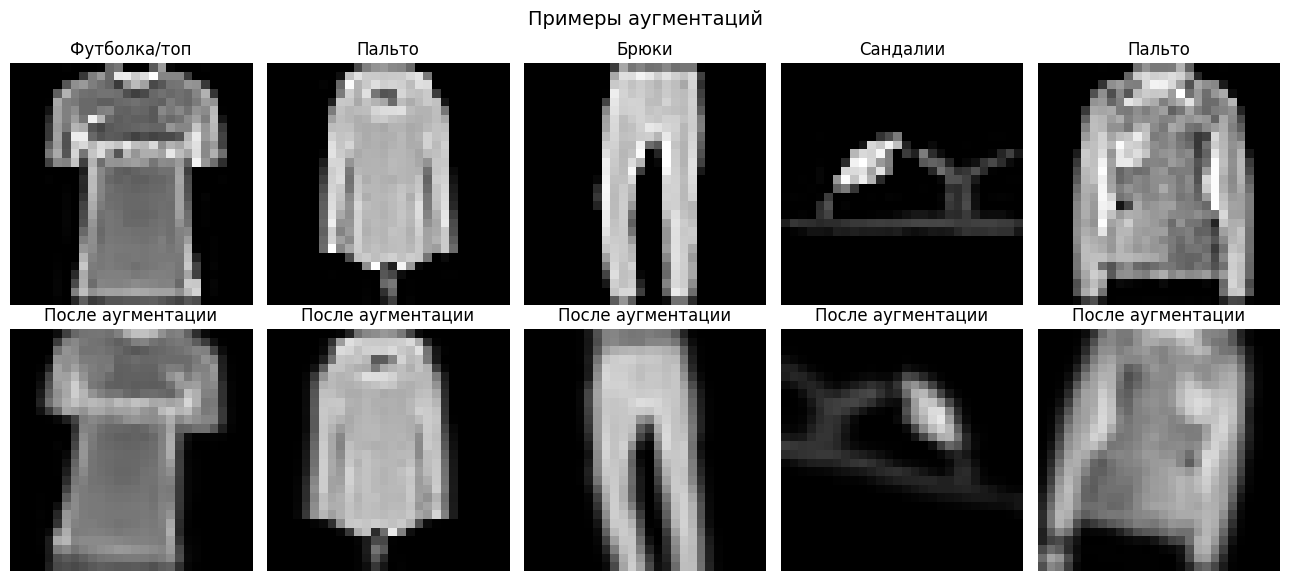

In [27]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(
    len(x_train),
    size=5,
    replace=False,
)

original_images = x_train[sample_indices]
original_labels = y_train[sample_indices]

augmented_images = data_augmentation(
    original_images,
    training=True,
).numpy()

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i in range(5):
    axes[0, i].imshow(
        original_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[0, i].set_title(class_names[original_labels[i]])
    axes[0, i].axis("off")

    axes[1, i].imshow(
        augmented_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, i].set_title("После аугментации")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("До", fontsize=12)
axes[1, 0].set_ylabel("После", fontsize=12)

plt.suptitle("Примеры аугментаций", fontsize=14)
plt.tight_layout()
plt.show()

### 3. Модель с аугментациями
Архитектуру CNN не меняем. Добавляем только слой аугментаций перед первым свёрточным слоем.

In [28]:
def build_augmented_cnn_model():
    inputs = tf.keras.layers.Input(shape=(28, 28, 1), name="input_image")
    
    # Работает только во время обучения
    x = data_augmentation(inputs)
    
    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="stem_conv")(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_1")(x)
    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="block_conv_1")(x)
    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="block_conv_2")(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_2")(x)
    x = tf.keras.layers.Conv2D(64, kernel_size=3, padding="same", activation="relu", name="final_conv")(x)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(64, activation="relu", name="classifier_dense")(x)
    x = tf.keras.layers.Dropout(0.30, name="classifier_dropout")(x)
    
    outputs = tf.keras.layers.Dense(10, activation="softmax", name="predictions")(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs, name="cnn_with_augmentation")
    

Создаем модель

In [29]:
tf.keras.utils.set_random_seed(SEED)

augmented_cnn_model = build_augmented_cnn_model()
augmented_cnn_model.summary()

Model: "cnn_with_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block_conv_1 (Conv2D)           │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block_conv_2 (Conv2D)           │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_conv (Conv2D)             │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,730 (932.54 KB)

 Trainable params: 238,730 (932.54 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Компиляция и обучение

In [30]:
augmented_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [31]:
augmentation_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="checkpoints/cnn_augmentation_best.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

In [32]:
augmentation_history = augmented_cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=augmentation_callbacks,
    verbose=1
)

histories["cnn_augmentation"] = augmentation_history
models["cnn_augmentation"] = augmented_cnn_model

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5804 - loss: 1.1395
Epoch 1: val_loss improved from None to 0.72476, saving model to checkpoints/cnn_augmentation_best.keras

Epoch 1: finished saving model to checkpoints/cnn_augmentation_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.6851 - loss: 0.8536 - val_accuracy: 0.7191 - val_loss: 0.7248
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7682 - loss: 0.6137
Epoch 2: val_loss improved from 0.72476 to 0.55147, saving model to checkpoints/cnn_augmentation_best.keras

Epoch 2: finished saving model to checkpoints/cnn_augmentation_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - accuracy: 0.7752 - loss: 0.5956 - val_accuracy: 0.7861 - val_loss: 0.5515
Epoch 3/30
390/391 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7944 - loss: 0.5450
Epoch 3: val_loss improved from 0.55147 to 0.49457, saving model to checkpoints/cnn_augmentation_best.keras

Epoch 3: finished saving mode

### 5. Графики

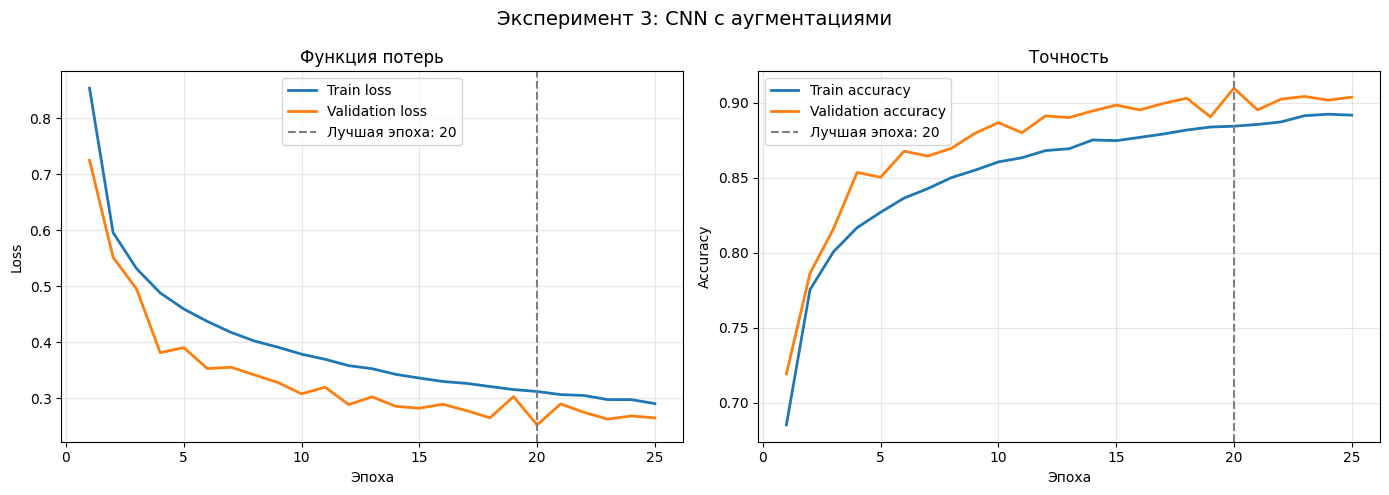

In [33]:
plot_training_history(augmentation_history, "Эксперимент 3: CNN с аугментациями")

### 6. Сохраняем результат

In [34]:
h = augmentation_history.history
best_index = int(np.argmin(h["val_loss"]))

experiment_results["cnn_augmentation"] = {
    "Номер": 3,
    "Модель": "CNN с аугментациями",
    "Параметры": augmented_cnn_model.count_params(),
    "Лучшая эпоха": best_index + 1,
    "Минимальный val_loss": float(h["val_loss"][best_index]),
    "val_accuracy": float(h["val_accuracy"][best_index]),
}

### Выводы

Модель с аугментациями содержит **238 730 параметров**. Лучший результат был получен на **29-й эпохе**: `validation loss` составил **0.2385**, а точность на валидационной выборке — **91.41%**.

Обучающая точность составила **89.84%**, что на **1.57 процентного пункта ниже** валидационной. Это нормально: во время обучения аугментации и Dropout усложняют данные, а при валидации они отключены.

По сравнению с CNN без аугментаций точность немного уменьшилась: с **92.03% до 91.41%**. При этом признаки переобучения стали менее заметны.

Модель обучалась медленнее и достигла лучшего результата только на 29-й эпохе. Это связано с тем, что аугментированные изображения сложнее исходных. В данном эксперименте аугментации уменьшили переобучение, но не повысили валидационную точность.

# CNN с остаточной связью

### 1. Слой аугментаций

In [35]:
residual_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(mode="horizontal",seed=SEED),
    tf.keras.layers.RandomTranslation(height_factor=0.08, width_factor=0.08, seed=SEED),
    tf.keras.layers.RandomRotation(factor=0.04, seed=SEED),
    tf.keras.layers.RandomZoom(height_factor=0.08, width_factor=0.08, seed=SEED)
], name="data_augmentation")

### 2. Модель с остаточной связью

In [36]:
def build_residual_cnn_model():
    inputs = tf.keras.layers.Input(shape=(28, 28, 1), name="input_image")

    x = residual_augmentation(inputs)

    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="stem_conv")(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_1")(x)

    # Сохраняем вход остаточного блока
    shortcut = x

    # Преобразование F(x)
    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="block_conv_1")(x)
    x = tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation=None, name="block_conv_2")(x)

    # F(x) + x
    x = tf.keras.layers.Add(name="skip_connection")([x, shortcut])
    
    x = tf.keras.layers.Activation("relu", name="block_output_relu")(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool_2")(x)
    x = tf.keras.layers.Conv2D(64, kernel_size=3, padding="same", activation="relu", name="final_conv")(x)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(64, activation="relu", name="classifier_dense")(x)
    x = tf.keras.layers.Dropout(0.30, name="classifier_dropout")(x)

    outputs = tf.keras.layers.Dense(10, activation="softmax", name="predictions")(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs, name="residual_cnn")

Создаем модель

In [37]:
tf.keras.utils.set_random_seed(SEED)

residual_cnn_model = build_residual_cnn_model()
residual_cnn_model.summary()

Model: "residual_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 28, 28, 1) │          0 │ input_image[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 28, 28,    │        320 │ data_augmentatio… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_1              │ (None, 14, 14,    │          0 │ stem_conv[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_conv_1        │ (None, 14, 14,    │      9,248 │ pool_1[0][0]      │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_conv_2        │ (None, 14, 14,    │      9,248 │ block_conv_1[0][… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection     │ (None, 14, 14,    │          0 │ block_conv_2[0][… │
│ (Add)               │ 32)               │            │ pool_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_output_relu   │ (None, 14, 14,    │          0 │ skip_connection[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_2              │ (None, 7, 7, 32)  │          0 │ block_output_rel… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_conv (Conv2D) │ (None, 7, 7, 64)  │     18,496 │ pool_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ final_conv[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 64)        │    200,768 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 64)        │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions (Dense) │ (None, 10)        │        650 │ classifier_dropo… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 238,730 (932.54 KB)

 Trainable params: 238,730 (932.54 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Компиляция

In [38]:
residual_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

### 4. Callback функции

In [39]:
residual_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="checkpoints/residual_cnn_best.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

### 5. Обучение

In [40]:
residual_history = residual_cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=residual_callbacks,
    verbose=1
)

histories["residual_cnn"] = residual_history
models["residual_cnn"] = residual_cnn_model

Epoch 1/30
390/391 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5725 - loss: 1.1773
Epoch 1: val_loss improved from None to 0.69276, saving model to checkpoints/residual_cnn_best.keras

Epoch 1: finished saving model to checkpoints/residual_cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.6772 - loss: 0.8815 - val_accuracy: 0.7409 - val_loss: 0.6928
Epoch 2/30
390/391 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7649 - loss: 0.6192
Epoch 2: val_loss improved from 0.69276 to 0.49127, saving model to checkpoints/residual_cnn_best.keras

Epoch 2: finished saving model to checkpoints/residual_cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - accuracy: 0.7720 - loss: 0.5994 - val_accuracy: 0.8120 - val_loss: 0.4913
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7964 - loss: 0.5355
Epoch 3: val_loss improved from 0.49127 to 0.46941, saving model to checkpoints/residual_cnn_best.keras

Epoch 3: finished saving model to checkpoints/res

### 6. Графики

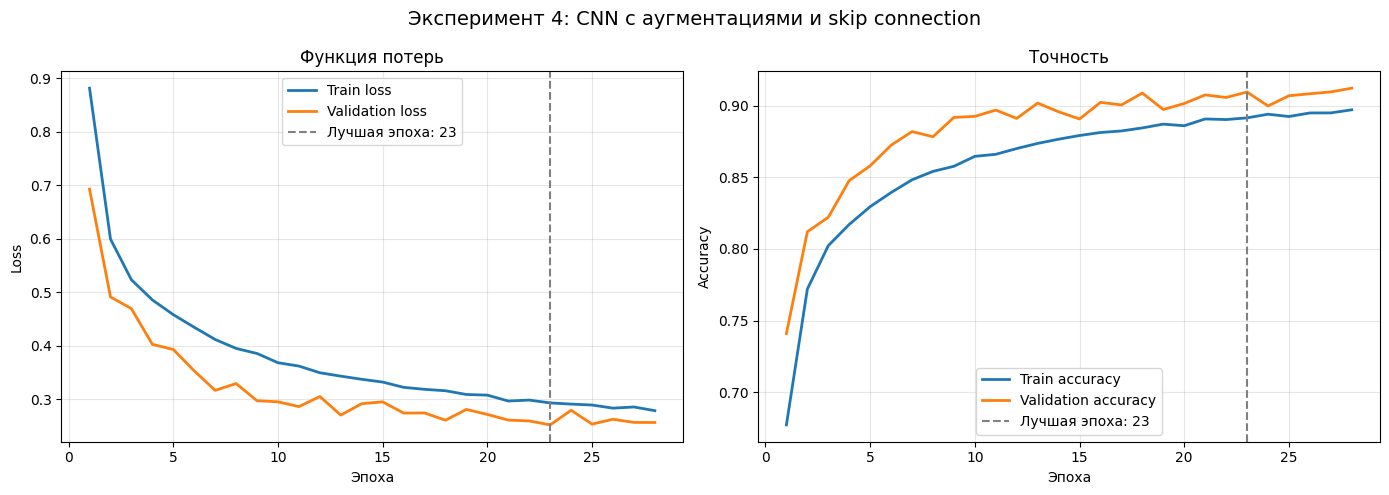

In [41]:
plot_training_history(residual_history, "Эксперимент 4: CNN с аугментациями и skip connection")

### 7. Сохранение результата

In [42]:
h = residual_history.history
best_index = int(np.argmin(h["val_loss"]))

experiment_results["residual_cnn"] = {
    "Номер": 4,
    "Модель": "CNN с аугментациями и skip connection",
    "Параметры": residual_cnn_model.count_params(),
    "Лучшая эпоха": best_index + 1,
    "Минимальный val_loss": float(h["val_loss"][best_index]),
    "val_accuracy": float(h["val_accuracy"][best_index]),
}

### Вывод
Модель с остаточной связью содержит **238 730 параметров**. Лучший результат был получен на **23-й эпохе**: `validation loss` составил **0.2522**, а точность на валидационной выборке — **90.95%**.

Обучающая точность составила **89.15%**, что на **1.80 процентного пункта ниже валидационной. Это объясняется тем, что во время обучения используются аугментации и Dropout, а во время валидации они отключены.

По сравнению с моделью без остаточной связи валидационная точность уменьшилась с **91.41% до 90.95%**, а `validation loss` увеличился с **0.2385 до 0.2522**.

Таким образом, в этом эксперименте остаточная связь не улучшила качество модели. Вероятно, сеть недостаточно глубокая, поэтому преимущество skip connection проявилось слабо.

# Сравнение всех моделей

### Проведем итоговую оценку на тестовой выборке

In [44]:
test_models = {
    "dense": dense_model,
    "cnn": cnn_model,
    "cnn_augmentation": augmented_cnn_model,
    "residual_cnn": residual_cnn_model
}

for model_key, model in test_models.items():
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    
    experiment_results[model_key]["test_loss"] = float(test_loss)
    experiment_results[model_key]["Точность на тесте"] = float(test_accuracy)
    
    print(f"{model_key}: " f"test_loss={test_loss:.4f}, " f"test_accuracy={test_accuracy:.4f}")

dense: test_loss=0.3258, test_accuracy=0.8835
cnn: test_loss=0.2439, test_accuracy=0.9142
cnn_augmentation: test_loss=0.2823, test_accuracy=0.8947
residual_cnn: test_loss=0.2782, test_accuracy=0.8986


### Построим итоговую таблицу

In [46]:
final_table = pd.DataFrame(experiment_results.values()).sort_values("Номер")

final_table = final_table[["Номер", "Модель", "Параметры", "Минимальный val_loss", "Точность на тесте"]]

final_table.style.format({
    "Параметры": "{:,.0f}",
    "Минимальный val_loss": "{:.4f}",
    "Точность на тесте": "{:.2%}"
})
final_table

,Номер,Модель,Параметры,Минимальный val_loss,Точность на тесте
0,1,Полносвязная сеть,235146,0.288408,0.8835
1,2,Сверточная сеть,238730,0.222984,0.9142
2,3,CNN с аугментациями,238730,0.251965,0.8947
3,4,CNN с аугментациями и skip connection,238730,0.252178,0.8986


### Выберем лучшую модель
По заданию лучшую модель выбираем по минимальному val_loss, а не по тестовой точности

In [47]:
best_key = min(experiment_results, key=lambda key: experiment_results[key]["Минимальный val_loss"])
best_result = experiment_results[best_key]

print("Лучшая модель: ", best_result["Модель"])
print("Минимальный val_loss:", f"{best_result['Минимальный val_loss']:.4f}")
print("Точность на тесте:", f"{best_result['Точность на тесте']:.2%}")

Лучшая модель:  Сверточная сеть
Минимальный val_loss: 0.2230
Точность на тесте: 91.42%


Почему не выбираем по тесту: тестовая выборка предназначена только для окончательной независимой оценки.

### Общий итог

В работе были обучены четыре модели для классификации изображений Fashion MNIST.

Полносвязная модель показала тестовую точность **88.35%**, но она не учитывает расположение соседних пикселей. Добавление свёрточных слоёв улучшило результат: тестовая точность выросла до **91.42%**, а `validation loss` уменьшился с **0.2884 до 0.2230**.

Аугментации сделали обучающие изображения более разнообразными и уменьшили переобучение, но в данном эксперименте не повысили качество. Тестовая точность модели с аугментациями составила **89.47%**.

Добавление остаточной связи также не улучшило результат по основному критерию: `validation loss` немного увеличился с **0.2520 до 0.2522**. При этом тестовая точность немного выросла с **89.47% до 89.86%**. Вероятно, сеть недостаточно глубокая, поэтому преимущество остаточной связи проявилось слабо.

Лучшей по минимальному `validation loss` стала обычная **свёрточная сеть без аугментаций и остаточной связи**. Её `validation loss` составил **0.2230**, а точность на тестовой выборке — **91.42%**.

Таким образом, наибольший вклад в качество дало добавление свёрточных слоёв. Аугментации и остаточная связь в выбранной архитектуре не привели к дальнейшему улучшению результата.